# Практическая работа № 7
## Разбиение данных и валидация моделей выявления кибератак

Решение выполнено на приложенном `soc_validation_practice.csv`. Код содержит комментарии; результаты и выводы расположены в текстовых ячейках. Выполняйте ячейки сверху вниз.

Случайная, групповая и временная схемы ниже — **три независимых учебных эксперимента** над одной выборкой `development`. Финальный тест хранится отдельно и не используется при выборе схем или настройке преобразователей.

## Исходные данные

Набор моделирует телеметрию офисных устройств и серверов за 120 дней с 1 сентября по 29 декабря 2025 года. 3600 событий образуют 480 групп разного размера (4, 6, 8 или 12 записей). После 60-го дня возрастает нормальная нагрузка. Атаки происходят неравномерно.

| Поля | Назначение |
|---|---|
| event_id | уникальный идентификатор строки |
| timestamp, window_start, window_end | регистрация и границы пятиминутного окна |
| host_id, host_role, user_id | узел, его роль и учётная запись |
| session_id | сессия связанных событий |
| incident_id, campaign_id | инцидент и кампания; пусты у нормальных событий |
| validation_group | сессия для нормы, целый инцидент для атаки |
| traffic_type | контекст активности |
| connections_per_min | соединения в минуту |
| unique_destinations | число уникальных адресатов |
| outbound_mb | исходящий трафик, Мбайт |
| failed_logins | число неуспешных входов |
| duration_sec | длительность активности, секунды |
| scenario, is_attack | учебный сценарий и метка 0/1 |
| dataset_part | development — первые 100 дней, final_test — последние 20 |
| day_index, hour, day_of_week | номер дня от 0, час, день недели от 0 |

Один атакующий инцидент включает две сессии; кампания объединяет несколько инцидентов. Поэтому группировка по session_id может разделить инцидент, а группировка по validation_group может разделить кампанию. Идентификаторы, время и контрольные поля не являются поведенческими признаками.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (
    train_test_split, StratifiedShuffleSplit, KFold, StratifiedKFold,
    RepeatedStratifiedKFold, GroupKFold, StratifiedGroupKFold,
    TimeSeriesSplit
)
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample

# Только эти пять столбцов описывают поведение события в учебных примерах.
FEATURES = [
    'connections_per_min', 'unique_destinations', 'outbound_mb',
    'failed_logins', 'duration_sec'
]
SEED = 42

data_path = Path('soc_validation_practice.csv')
if not data_path.exists():
    raise FileNotFoundError('Положите soc_validation_practice.csv рядом с блокнотом')

In [2]:
# Даты сразу переводим из текста в тип datetime.
df = pd.read_csv(data_path, parse_dates=['timestamp', 'window_start', 'window_end'])
display(df.head())

,event_id,timestamp,window_start,window_end,host_id,host_role,user_id,session_id,incident_id,campaign_id,...,unique_destinations,outbound_mb,failed_logins,duration_sec,scenario,is_attack,dataset_part,day_index,hour,day_of_week
0,pz-event-00001,2025-09-01 08:00:00,2025-09-01 07:55:00,2025-09-01 08:00:00,host-pz-21,server,account-pz-21,session-pz-0000,NaN,NaN,...,13,35.74,1,213.02,normal,0,development,0,8,0
1,pz-event-00002,2025-09-01 08:05:00,2025-09-01 08:00:00,2025-09-01 08:05:00,host-pz-21,server,account-pz-21,session-pz-0000,NaN,NaN,...,15,42.31,1,173.70,normal,0,development,0,8,0
2,pz-event-00003,2025-09-01 08:10:00,2025-09-01 08:05:00,2025-09-01 08:10:00,host-pz-21,server,account-pz-21,session-pz-0000,NaN,NaN,...,12,44.73,0,228.77,normal,0,development,0,8,0
3,pz-event-00004,2025-09-01 08:15:00,2025-09-01 08:10:00,2025-09-01 08:15:00,host-pz-21,server,account-pz-21,session-pz-0000,NaN,NaN,...,15,40.82,1,205.62,normal,0,development,0,8,0
4,pz-event-00005,2025-09-01 10:00:00,2025-09-01 09:55:00,2025-09-01 10:00:00,host-pz-23,server,account-pz-23,session-pz-0001,NaN,NaN,...,10,39.58,0,167.03,normal,0,development,0,10,0


## Вспомогательные функции

Функции ниже одинаково считают размер, долю атак и пересечения для всех схем. `split()` возвращает **позиции строк**, поэтому при извлечении строк используется `.iloc`.

In [3]:
def overlap(first, second, column='validation_group'):
    # Пустой incident_id или campaign_id означает отсутствие атаки.
    left = set(first[column].dropna())
    right = set(second[column].dropna())
    return len(left & right)


def describe(name, data):
    # Одна строка сводки для одной части данных.
    return {
        'part': name,
        'events': len(data),
        'groups': data['validation_group'].nunique(),
        'attacks': int(data['is_attack'].sum()),
        'attack_percent': 100 * data['is_attack'].mean(),
        'start': data['timestamp'].min(),
        'end': data['timestamp'].max()
    }


def partition_report(parts):
    # Сначала размеры, затем пересечения каждой пары частей.
    display(pd.DataFrame([describe(name, part) for name, part in parts.items()]))
    names = list(parts)
    rows = []
    for i, first in enumerate(names):
        for second in names[i + 1:]:
            rows.append({
                'pair': first + ' / ' + second,
                'shared_events': overlap(parts[first], parts[second], 'event_id'),
                'shared_groups': overlap(parts[first], parts[second]),
                'shared_incidents': overlap(parts[first], parts[second], 'incident_id'),
                'shared_campaigns': overlap(parts[first], parts[second], 'campaign_id')
            })
    display(pd.DataFrame(rows))


def analyze(data, splits):
    # Для каждого блока сравниваем train и validation.
    rows = []
    for fold, (train_idx, val_idx) in enumerate(splits, 1):
        train_part = data.iloc[train_idx]
        val_part = data.iloc[val_idx]
        rows.append({
            'fold': fold,
            'train_size': len(train_part),
            'validation_size': len(val_part),
            'validation_attacks': int(val_part['is_attack'].sum()),
            'validation_attack_percent': 100 * val_part['is_attack'].mean(),
            'shared_groups': overlap(train_part, val_part),
            'shared_incidents': overlap(train_part, val_part, 'incident_id'),
            'shared_campaigns': overlap(train_part, val_part, 'campaign_id'),
            'train_start': train_part['timestamp'].min(),
            'train_end': train_part['timestamp'].max(),
            'validation_start': val_part['timestamp'].min(),
            'validation_end': val_part['timestamp'].max()
        })
    return pd.DataFrame(rows)


def coverage(number_of_rows, splits):
    # Считаем, сколько раз каждая строка использовалась для validation.
    counts = np.zeros(number_of_rows, dtype=int)
    for _, val_idx in splits:
        counts[val_idx] += 1
    return counts


def show_blocks(name, data, splits):
    table = analyze(data, splits)
    print(name)
    display(table)
    counts = coverage(len(data), splits)
    print('Попадания в validation: min =', counts.min(),
          ', max =', counts.max(), ', ни разу =', int((counts == 0).sum()))
    return table

## Задание 1. Аудит данных и отделение финального теста — 10 минут, 3 балла

1. Загрузить CSV с преобразованием временных столбцов; проверить размер, уникальность event_id и пропуски
2. Отделить development и final_test; показать числа событий, групп, атак и временные границы
3. Проверить отсутствие общих event_id, validation_group и incident_id между development и test
4. Указать пять поведенческих признаков и назначение остальных полей

**Проверяемый результат:** Таблица состава данных, 3000 событий development и 600 событий test, нулевые пересечения и объяснение назначения полей.


In [4]:
# Первичный аудит до любых разбиений.
print('Размер:', df.shape)
print('Полных дубликатов:', int(df.duplicated().sum()))
print('Уникален ли event_id:', df['event_id'].is_unique)
display(df.isna().sum().to_frame('Пропусков'))

# Финальный тест отделяем заранее по готовой метке dataset_part.
development = df[df['dataset_part'] == 'development'].copy().reset_index(drop=True)
test = df[df['dataset_part'] == 'final_test'].copy().reset_index(drop=True)
partition_report({'development': development, 'final_test': test})

assert len(development) == 3000 and len(test) == 600
assert df['event_id'].is_unique
assert overlap(development, test, 'event_id') == 0
assert overlap(development, test) == 0
assert overlap(development, test, 'incident_id') == 0
assert development['timestamp'].max() < test['timestamp'].min()
print('Пять поведенческих признаков:', ', '.join(FEATURES))

Размер: (3600, 23)
Полных дубликатов: 0
Уникален ли event_id: True


,Пропусков
event_id,0
timestamp,0
window_start,0
window_end,0
host_id,0
host_role,0
user_id,0
session_id,0
incident_id,3260
campaign_id,3260


,part,events,groups,attacks,attack_percent,start,end
0,development,3000,400,252,8.400000,2025-09-01 08:00:00,2025-12-09 19:55:00
1,final_test,600,80,88,14.666667,2025-12-10 08:00:00,2025-12-29 19:55:00


,pair,shared_events,shared_groups,shared_incidents,shared_campaigns
0,development / final_test,0,0,0,1


Пять поведенческих признаков: connections_per_min, unique_destinations, outbound_mb, failed_logins, duration_sec


### Вывод по заданию 1

В наборе 3600 строк и 23 столбца; `event_id` уникален, полных дубликатов нет. Пустые `incident_id` и `campaign_id` у 3260 нормальных событий означают отсутствие атаки, а не потерю измерения. `Development` содержит 3000 событий, 400 групп и 252 атаки (8,4%); финальный тест — 600 событий, 80 групп и 88 атак (14,7%). Между ними нет общих `event_id`, `validation_group` и `incident_id`, но есть одна общая кампания: тест проверяет будущие события, а не полностью новые кампании. Пять столбцов `FEATURES` описывают поведение; `is_attack` — метка, `validation_group` — единица группировки, а идентификаторы, время, сценарий и `dataset_part` служат для контроля разбиения и не подаются в модель как поведенческие признаки.

## Задание 2. Случайное разбиение и стратификация — 15 минут, 4 балла

1. Сформировать train, validation и calibration в долях 60/20/20 от development без стратификации и со стратификацией по is_attack
2. Сравнить доли атак, пересечения групп и инцидентов; найти конкретный разделённый инцидент
3. По готовому примеру StratifiedShuffleSplit проверить покрытие событий за пять повторений после фиксации calibration
4. По готовому примеру Bootstrap определить размер train, число уникальных событий и размер Out-of-Bag

**Проверяемый результат:** Два варианта 1800/600/600, отчёт об утечке связанных событий, счётчики покрытия и пояснение Bootstrap.


In [5]:
random_parts = {}

for name, use_stratification in [
    ('Random Hold-out', False),
    ('Stratified Hold-out', True)
]:
    # Сначала фиксируем 20% development как calibration.
    labels = development['is_attack'] if use_stratification else None
    remaining_part, calibration = train_test_split(
        development, test_size=0.20, random_state=SEED, stratify=labels
    )

    # От оставшихся 80% берём четверть: это ещё 20% от development.
    labels = remaining_part['is_attack'] if use_stratification else None
    train_part, validation = train_test_split(
        remaining_part, test_size=0.25, random_state=SEED, stratify=labels
    )
    parts_for_scheme = {
        'train': train_part.reset_index(drop=True),
        'validation': validation.reset_index(drop=True),
        'calibration': calibration.reset_index(drop=True)
    }
    random_parts[name] = parts_for_scheme
    print()
    print(name)
    partition_report(parts_for_scheme)
    assert [len(parts_for_scheme[key]) for key in
            ['train', 'validation', 'calibration']] == [1800, 600, 600]

    # Показываем конкретный инцидент, разделённый между train и validation.
    shared = set(parts_for_scheme['train']['incident_id'].dropna()) & set(
        parts_for_scheme['validation']['incident_id'].dropna()
    )
    if shared:
        incident = sorted(shared)[0]
        print('Пример разделённого инцидента:', incident)
        print('Строк в train:', int((parts_for_scheme['train']['incident_id'] == incident).sum()),
              '| в validation:', int((parts_for_scheme['validation']['incident_id'] == incident).sum()))

# Следующая ячейка использует только стратифицированный эксперимент.
parts = random_parts['Stratified Hold-out']


Random Hold-out


,part,events,groups,attacks,attack_percent,start,end
0,train,1800,395,143,7.944444,2025-09-01 08:10:00,2025-12-09 19:45:00
1,validation,600,305,56,9.333333,2025-09-01 08:05:00,2025-12-09 19:50:00
2,calibration,600,300,53,8.833333,2025-09-01 08:00:00,2025-12-09 19:55:00


,pair,shared_events,shared_groups,shared_incidents,shared_campaigns
0,train / validation,0,300,22,7
1,train / calibration,0,295,24,7
2,validation / calibration,0,232,22,7


Пример разделённого инцидента: inc-pz-0014
Строк в train: 4 | в validation: 2

Stratified Hold-out


,part,events,groups,attacks,attack_percent,start,end
0,train,1800,391,152,8.444444,2025-09-01 08:00:00,2025-12-09 19:50:00
1,validation,600,314,50,8.333333,2025-09-01 10:20:00,2025-12-09 19:55:00
2,calibration,600,306,50,8.333333,2025-09-01 08:05:00,2025-12-09 19:20:00


,pair,shared_events,shared_groups,shared_incidents,shared_campaigns
0,train / validation,0,305,21,6
1,train / calibration,0,297,22,7
2,validation / calibration,0,245,19,6


Пример разделённого инцидента: inc-pz-0014
Строк в train: 5 | в validation: 1


In [6]:
# Calibration остаётся неизменной во всех пяти повторениях.
remaining = pd.concat([parts['train'], parts['validation']]).reset_index(drop=True)
sss = StratifiedShuffleSplit(n_splits=5, test_size=0.25, random_state=SEED)
repeat_splits = list(sss.split(remaining[FEATURES], remaining['is_attack']))
repeat_table = show_blocks('StratifiedShuffleSplit', remaining, repeat_splits)
repeat_counts = coverage(len(remaining), repeat_splits)

# Bootstrap выбирает строки с возвращением: одна строка может встретиться несколько раз.
boot_train = resample(
    remaining, replace=True, n_samples=len(remaining), random_state=SEED
)
oob = remaining.loc[~remaining.index.isin(boot_train.index)]
print('Bootstrap: строк =', len(boot_train),
      '| уникальных событий =', boot_train.index.nunique(),
      '| OOB =', len(oob),
      '| OOB % =', round(100 * len(oob) / len(remaining), 2))
print('Общих event_id:', overlap(boot_train, oob, 'event_id'),
      '| общих групп:', overlap(boot_train, oob))

StratifiedShuffleSplit


,fold,train_size,validation_size,validation_attacks,validation_attack_percent,shared_groups,shared_incidents,shared_campaigns,train_start,train_end,validation_start,validation_end
0,1,1800,600,50,8.333333,306,20,7,2025-09-01 08:00:00,2025-12-09 19:55:00,2025-09-01 14:35:00,2025-12-09 19:35:00
1,2,1800,600,50,8.333333,310,23,6,2025-09-01 08:00:00,2025-12-09 19:50:00,2025-09-01 10:20:00,2025-12-09 19:55:00
2,3,1800,600,51,8.500000,304,20,5,2025-09-01 08:10:00,2025-12-09 19:55:00,2025-09-01 08:00:00,2025-12-09 19:30:00
3,4,1800,600,51,8.500000,314,23,6,2025-09-01 08:00:00,2025-12-09 19:55:00,2025-09-01 08:10:00,2025-12-09 19:50:00
4,5,1800,600,50,8.333333,304,21,5,2025-09-01 08:15:00,2025-12-09 19:55:00,2025-09-01 08:00:00,2025-12-09 19:50:00


Попадания в validation: min = 0 , max = 5 , ни разу = 598
Bootstrap: строк = 2400 | уникальных событий = 1495 | OOB = 905 | OOB % = 37.71
Общих event_id: 0 | общих групп: 345


### Вывод по заданию 2

Оба Hold-out дают размеры 1800/600/600. Без стратификации доли атак в train, validation и calibration равны 7,94%, 9,33% и 8,83%; со стратификацией — 8,44%, 8,33% и 8,33%. Баланс классов стал ровнее, но в стратифицированном варианте train и validation разделяют 305 групп и 21 инцидент; например, `inc-pz-0014` имеет пять строк в train и одну в validation. В случайном варианте пересекаются 300 групп и 22 инцидента. При пяти повторениях `StratifiedShuffleSplit` calibration остаётся фиксированной, а 598 из 2400 оставшихся событий ни разу не попали в validation. Bootstrap выбрал 2400 строк с возвращением, но только 1495 уникальных событий; OOB содержит 905 событий (37,71%) и не делит с bootstrap-train ни одной строки, зато разделяет 345 групп. Следовательно, отсутствие общих строк не устраняет утечку связанных событий.

## Задание 3. Кросс-валидация по блокам и группам — 20 минут, 6 балла

1. Случайно выбрать 20 % уникальных validation_group для calibration целиком и оставить остальные группы в cv_pool
2. На одном cv_pool сравнить KFold, StratifiedKFold, GroupKFold и StratifiedGroupKFold с пятью блоками
3. Для каждого блока показать размеры, долю атак, общие группы, инциденты и кампании
4. Проверить однократное покрытие событий в KFold и GroupKFold; по готовому примеру RepeatedStratifiedKFold подтвердить покрытие дважды
5. На первом разбиении GroupKFold обучить StandardScaler только по train_idx и преобразовать validation_idx
6. Объяснить, почему разделение по инциденту не гарантирует разделение по кампании или по времени

**Проверяемый результат:** Четыре таблицы блоков, нулевые пересечения групп и инцидентов в групповых методах, проверка покрытия и корректное масштабирование.


In [7]:
# Выбираем 20% групп целиком, а не 20% отдельных строк.
group_ids = development['validation_group'].drop_duplicates()
calibration_groups = group_ids.sample(frac=0.20, random_state=SEED)
calibration_mask = development['validation_group'].isin(calibration_groups)
group_calibration = development.loc[calibration_mask].copy().reset_index(drop=True)
cv_pool = development.loc[~calibration_mask].copy().reset_index(drop=True)

print('Групп в development:', len(group_ids))
print('Групп в calibration:', group_calibration['validation_group'].nunique())
print('Событий в calibration:', len(group_calibration),
      '| событий в cv_pool:', len(cv_pool))
print('Общих групп:', overlap(group_calibration, cv_pool),
      '| общих инцидентов:', overlap(group_calibration, cv_pool, 'incident_id'),
      '| общих кампаний:', overlap(group_calibration, cv_pool, 'campaign_id'))
assert overlap(group_calibration, cv_pool) == 0
assert overlap(group_calibration, cv_pool, 'incident_id') == 0

Групп в development: 400
Групп в calibration: 80
Событий в calibration: 546 | событий в cv_pool: 2454
Общих групп: 0 | общих инцидентов: 0 | общих кампаний: 1


In [8]:
# Все четыре метода применяем к одному и тому же cv_pool.
X = cv_pool[FEATURES]
y = cv_pool['is_attack']
groups = cv_pool['validation_group']

all_splits = {
    'KFold': list(KFold(n_splits=5, shuffle=True, random_state=SEED).split(X)),
    'StratifiedKFold': list(StratifiedKFold(
        n_splits=5, shuffle=True, random_state=SEED
    ).split(X, y)),
    'GroupKFold': list(GroupKFold(n_splits=5).split(X, y, groups)),
    'StratifiedGroupKFold': list(StratifiedGroupKFold(
        n_splits=5, shuffle=True, random_state=SEED
    ).split(X, y, groups))
}

block_tables = {}
for name, splits in all_splits.items():
    block_tables[name] = show_blocks(name, cv_pool, splits)

# В обычных и групповых KFold каждая строка проверяется ровно один раз.
for name in ['KFold', 'GroupKFold']:
    counts = coverage(len(cv_pool), all_splits[name])
    assert np.all(counts == 1)
    print(name, ': однократное покрытие подтверждено')

for name in ['GroupKFold', 'StratifiedGroupKFold']:
    assert block_tables[name]['shared_groups'].eq(0).all()
    assert block_tables[name]['shared_incidents'].eq(0).all()

KFold


,fold,train_size,validation_size,validation_attacks,validation_attack_percent,shared_groups,shared_incidents,shared_campaigns,train_start,train_end,validation_start,validation_end
0,1,1963,491,52,10.590631,248,20,6,2025-09-01 10:00:00,2025-12-09 19:55:00,2025-09-01 19:20:00,2025-12-09 19:15:00
1,2,1963,491,46,9.368635,246,19,5,2025-09-01 10:00:00,2025-12-09 19:55:00,2025-09-01 14:10:00,2025-12-09 19:45:00
2,3,1963,491,40,8.146640,242,18,6,2025-09-01 10:00:00,2025-12-09 19:45:00,2025-09-01 10:10:00,2025-12-09 19:55:00
3,4,1963,491,48,9.775967,249,20,7,2025-09-01 10:05:00,2025-12-09 19:55:00,2025-09-01 10:00:00,2025-12-09 19:40:00
4,5,1964,490,58,11.836735,247,21,7,2025-09-01 10:00:00,2025-12-09 19:55:00,2025-09-01 10:05:00,2025-12-09 14:25:00


Попадания в validation: min = 1 , max = 1 , ни разу = 0
StratifiedKFold


,fold,train_size,validation_size,validation_attacks,validation_attack_percent,shared_groups,shared_incidents,shared_campaigns,train_start,train_end,validation_start,validation_end
0,1,1963,491,49,9.979633,242,20,7,2025-09-01 10:00:00,2025-12-09 19:55:00,2025-09-01 10:15:00,2025-12-09 19:15:00
1,2,1963,491,49,9.979633,247,20,5,2025-09-01 10:05:00,2025-12-09 19:50:00,2025-09-01 10:00:00,2025-12-09 19:55:00
2,3,1963,491,49,9.979633,247,20,6,2025-09-01 10:00:00,2025-12-09 19:55:00,2025-09-01 14:10:00,2025-12-09 19:50:00
3,4,1963,491,49,9.979633,255,19,6,2025-09-01 10:00:00,2025-12-09 19:55:00,2025-09-01 10:05:00,2025-12-09 19:35:00
4,5,1964,490,48,9.795918,245,20,6,2025-09-01 10:00:00,2025-12-09 19:55:00,2025-09-01 14:15:00,2025-12-09 19:30:00


Попадания в validation: min = 1 , max = 1 , ни разу = 0
GroupKFold


,fold,train_size,validation_size,validation_attacks,validation_attack_percent,shared_groups,shared_incidents,shared_campaigns,train_start,train_end,validation_start,validation_end
0,1,1962,492,60,12.195122,0,0,3,2025-09-01 10:00:00,2025-12-09 19:55:00,2025-09-01 19:00:00,2025-12-07 10:25:00
1,2,1962,492,44,8.943089,0,0,2,2025-09-01 10:00:00,2025-12-09 19:55:00,2025-09-01 14:00:00,2025-12-08 10:25:00
2,3,1964,490,44,8.979592,0,0,3,2025-09-01 10:00:00,2025-12-09 14:35:00,2025-09-02 14:00:00,2025-12-09 19:55:00
3,4,1964,490,44,8.979592,0,0,4,2025-09-01 14:00:00,2025-12-09 19:55:00,2025-09-01 10:00:00,2025-12-09 14:35:00
4,5,1964,490,52,10.612245,0,0,2,2025-09-01 10:00:00,2025-12-09 19:55:00,2025-09-02 19:00:00,2025-12-09 10:25:00


Попадания в validation: min = 1 , max = 1 , ни разу = 0
StratifiedGroupKFold


,fold,train_size,validation_size,validation_attacks,validation_attack_percent,shared_groups,shared_incidents,shared_campaigns,train_start,train_end,validation_start,validation_end
0,1,1982,472,28,5.932203,0,0,2,2025-09-01 10:00:00,2025-12-09 19:55:00,2025-09-01 19:00:00,2025-12-09 14:35:00
1,2,1940,514,48,9.338521,0,0,4,2025-09-01 10:00:00,2025-12-09 14:35:00,2025-09-03 14:00:00,2025-12-09 19:55:00
2,3,1948,506,60,11.857708,0,0,3,2025-09-01 10:00:00,2025-12-09 19:55:00,2025-09-03 08:00:00,2025-12-09 10:25:00
3,4,1950,504,48,9.523810,0,0,2,2025-09-01 10:00:00,2025-12-09 19:55:00,2025-09-02 14:00:00,2025-12-07 10:25:00
4,5,1996,458,60,13.100437,0,0,3,2025-09-01 19:00:00,2025-12-09 19:55:00,2025-09-01 10:00:00,2025-12-08 10:25:00


Попадания в validation: min = 1 , max = 1 , ни разу = 0
KFold : однократное покрытие подтверждено
GroupKFold : однократное покрытие подтверждено


In [9]:
# Повторный стратифицированный KFold: пять блоков в каждом из двух повторений.
repeated = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
repeated_splits = list(repeated.split(X, y))
repeated_counts = coverage(len(cv_pool), repeated_splits)
print('RepeatedStratifiedKFold: min =', repeated_counts.min(),
      ', max =', repeated_counts.max())
assert np.all(repeated_counts == 2)

RepeatedStratifiedKFold: min = 2 , max = 2


In [10]:
# Берём первый блок групповой проверки.
train_idx, validation_idx = all_splits['GroupKFold'][0]
scaler = StandardScaler()

# Среднее и стандартное отклонение scaler узнаёт только по train_idx.
X_train_scaled = scaler.fit_transform(X.iloc[train_idx])
X_validation_scaled = scaler.transform(X.iloc[validation_idx])
print('Размер обучающей матрицы:', X_train_scaled.shape)
print('Размер проверочной матрицы:', X_validation_scaled.shape)
display(pd.Series(scaler.mean_, index=FEATURES, name='Среднее train для scaler'))
print('Среднее первого признака после масштабирования train:',
      round(float(X_train_scaled[:, 0].mean()), 8))

Размер обучающей матрицы: (1962, 5)
Размер проверочной матрицы: (492, 5)


connections_per_min     42.436330
unique_destinations     11.313456
outbound_mb             17.339760
failed_logins            0.627421
duration_sec           109.720270
Name: Среднее train для scaler, dtype: float64

Среднее первого признака после масштабирования train: -0.0


### Вывод по заданию 3

Для групповой calibration выбраны 80 из 400 групп: в ней 546 событий, в `cv_pool` — 2454. Между ними нет общих групп и инцидентов, но есть одна общая кампания. У KFold и StratifiedKFold обучающая и проверочная части каждого блока разделяют сотни групп и 18–21 инцидент; стратификация удерживает долю атак примерно в диапазоне 9,80–9,98%, но не решает утечку. GroupKFold и StratifiedGroupKFold дают ноль общих групп и инцидентов в каждом блоке, однако разделяют 2–4 кампании и не гарантируют одинаковую долю атак. В обычном KFold и GroupKFold каждое событие попало в validation один раз, а в двух повторениях RepeatedStratifiedKFold — ровно дважды. `StandardScaler` в первом блоке GroupKFold обучен только на 1962 строках train и затем применён к 492 строкам validation. Группировка по `host_id` проверяла бы новые узлы, но не обязательно удержала бы целый инцидент; группировка по `campaign_id` защищала бы от пересечения кампаний, однако для нормальных событий без кампании потребовался бы отдельный ключ, например сессия.

## Задание 4. Хронологическая и временная кросс-валидация — 20 минут, 5 балла

1. Отсортировать development по времени; последние 20 % событий отложить для calibration
2. В оставшихся 2400 событиях сформировать хронологический Hold-out 80/20
3. Сравнить TimeSeriesSplit с расширяющимся и скользящим train: пять validation по 300 событий, max_train_size=800 для скользящего окна
4. Применить готовый генератор четырёх непересекающихся циклов: 12 дней train и 8 дней validation
5. Проверить хронологический порядок, пересечения групп и инцидентов и покрытие событий; построить временную схему окон средствами matplotlib
6. Объяснить неполное покрытие самых ранних событий и отсутствие гарантии сохранения долей атак

**Проверяемый результат:** Таблицы временных границ, график окон, 900 начальных событий вне validation в TimeSeriesSplit и вывод о групповых ограничениях.


In [11]:
# Отдельный временной эксперимент начинается заново с development.
time_sorted = development.sort_values('timestamp').reset_index(drop=True)
calibration_start = int(len(time_sorted) * 0.80)
time_pool = time_sorted.iloc[:calibration_start].copy().reset_index(drop=True)
time_calibration = time_sorted.iloc[calibration_start:].copy().reset_index(drop=True)

# Последние 20% time_pool идут в хронологическую validation.
validation_start = int(len(time_pool) * 0.80)
chron_train = time_pool.iloc[:validation_start].copy().reset_index(drop=True)
chron_validation = time_pool.iloc[validation_start:].copy().reset_index(drop=True)

partition_report({
    'chron_train': chron_train,
    'chron_validation': chron_validation,
    'time_calibration': time_calibration,
    'final_test': test
})
assert [len(chron_train), len(chron_validation), len(time_calibration), len(test)] == [1920, 480, 600, 600]
assert chron_train['timestamp'].max() < chron_validation['timestamp'].min()
assert chron_validation['timestamp'].max() < time_calibration['timestamp'].min()
assert time_calibration['timestamp'].max() < test['timestamp'].min()

,part,events,groups,attacks,attack_percent,start,end
0,chron_train,1920,256,168,8.750000,2025-09-01 08:00:00,2025-11-03 19:55:00
1,chron_validation,480,64,68,14.166667,2025-11-04 08:00:00,2025-11-19 19:55:00
2,time_calibration,600,80,16,2.666667,2025-11-20 08:00:00,2025-12-09 19:55:00
3,final_test,600,80,88,14.666667,2025-12-10 08:00:00,2025-12-29 19:55:00


,pair,shared_events,shared_groups,shared_incidents,shared_campaigns
0,chron_train / chron_validation,0,0,0,0
1,chron_train / time_calibration,0,0,0,0
2,chron_train / final_test,0,0,0,0
3,chron_validation / time_calibration,0,0,0,0
4,chron_validation / final_test,0,0,0,0
5,time_calibration / final_test,0,0,0,1


In [12]:
def blocked_time_splits(data, n_splits=4, train_days=12, validation_days=8):
    # Каждый цикл занимает 20 календарных дней; интервалы полуоткрытые.
    origin = data['timestamp'].min().normalize()
    cycle = pd.Timedelta(days=train_days + validation_days)
    for number in range(n_splits):
        start = origin + number * cycle
        middle = start + pd.Timedelta(days=train_days)
        end = start + cycle
        train_idx = np.flatnonzero(
            (data['timestamp'] >= start) & (data['timestamp'] < middle)
        )
        validation_idx = np.flatnonzero(
            (data['timestamp'] >= middle) & (data['timestamp'] < end)
        )
        yield train_idx, validation_idx

In [13]:
# Два TimeSeriesSplit отличаются только длиной train.
expanding = TimeSeriesSplit(n_splits=5, test_size=300)
sliding = TimeSeriesSplit(n_splits=5, test_size=300, max_train_size=800)
time_splits = {
    'Expanding TimeSeriesSplit': list(expanding.split(time_pool)),
    'Sliding TimeSeriesSplit': list(sliding.split(time_pool)),
    'Blocked 12/8 days': list(blocked_time_splits(time_pool))
}

time_tables = {}
for name, splits in time_splits.items():
    for train_idx, val_idx in splits:
        assert len(train_idx) > 0 and len(val_idx) > 0
        assert time_pool.iloc[train_idx]['timestamp'].max() < time_pool.iloc[val_idx]['timestamp'].min()
    time_tables[name] = show_blocks(name, time_pool, splits)
    counts = coverage(len(time_pool), splits)
    print('Не попало в validation:', int((counts == 0).sum()))

for name in ['Expanding TimeSeriesSplit', 'Sliding TimeSeriesSplit']:
    counts = coverage(len(time_pool), time_splits[name])
    assert int((counts == 0).sum()) == 900

Expanding TimeSeriesSplit


,fold,train_size,validation_size,validation_attacks,validation_attack_percent,shared_groups,shared_incidents,shared_campaigns,train_start,train_end,validation_start,validation_end
0,1,900,300,8,2.666667,0,0,0,2025-09-01 08:00:00,2025-09-30 19:55:00,2025-10-01 08:00:00,2025-10-10 19:55:00
1,2,1200,300,68,22.666667,0,0,0,2025-09-01 08:00:00,2025-10-10 19:55:00,2025-10-11 08:00:00,2025-10-20 19:55:00
2,3,1500,300,8,2.666667,0,0,1,2025-09-01 08:00:00,2025-10-20 19:55:00,2025-10-21 08:00:00,2025-10-30 19:55:00
3,4,1800,300,8,2.666667,0,0,0,2025-09-01 08:00:00,2025-10-30 19:55:00,2025-10-31 08:00:00,2025-11-09 19:55:00
4,5,2100,300,60,20.000000,0,0,1,2025-09-01 08:00:00,2025-11-09 19:55:00,2025-11-10 08:00:00,2025-11-19 19:55:00


Попадания в validation: min = 0 , max = 1 , ни разу = 900
Не попало в validation: 900
Sliding TimeSeriesSplit


,fold,train_size,validation_size,validation_attacks,validation_attack_percent,shared_groups,shared_incidents,shared_campaigns,train_start,train_end,validation_start,validation_end
0,1,800,300,8,2.666667,0,0,0,2025-09-04 14:00:00,2025-09-30 19:55:00,2025-10-01 08:00:00,2025-10-10 19:55:00
1,2,800,300,68,22.666667,0,0,0,2025-09-14 14:00:00,2025-10-10 19:55:00,2025-10-11 08:00:00,2025-10-20 19:55:00
2,3,800,300,8,2.666667,0,0,1,2025-09-24 14:00:00,2025-10-20 19:55:00,2025-10-21 08:00:00,2025-10-30 19:55:00
3,4,800,300,8,2.666667,0,0,0,2025-10-04 14:00:00,2025-10-30 19:55:00,2025-10-31 08:00:00,2025-11-09 19:55:00
4,5,800,300,60,20.000000,0,0,1,2025-10-14 14:00:00,2025-11-09 19:55:00,2025-11-10 08:00:00,2025-11-19 19:55:00


Попадания в validation: min = 0 , max = 1 , ни разу = 900
Не попало в validation: 900
Blocked 12/8 days


,fold,train_size,validation_size,validation_attacks,validation_attack_percent,shared_groups,shared_incidents,shared_campaigns,train_start,train_end,validation_start,validation_end
0,1,360,240,8,3.333333,0,0,1,2025-09-01 08:00:00,2025-09-12 19:55:00,2025-09-13 08:00:00,2025-09-20 19:55:00
1,2,360,240,8,3.333333,0,0,0,2025-09-21 08:00:00,2025-10-02 19:55:00,2025-10-03 08:00:00,2025-10-10 19:55:00
2,3,360,240,8,3.333333,0,0,1,2025-10-11 08:00:00,2025-10-22 19:55:00,2025-10-23 08:00:00,2025-10-30 19:55:00
3,4,360,240,36,15.000000,0,0,1,2025-10-31 08:00:00,2025-11-11 19:55:00,2025-11-12 08:00:00,2025-11-19 19:55:00


Попадания в validation: min = 0 , max = 1 , ни разу = 1440
Не попало в validation: 1440


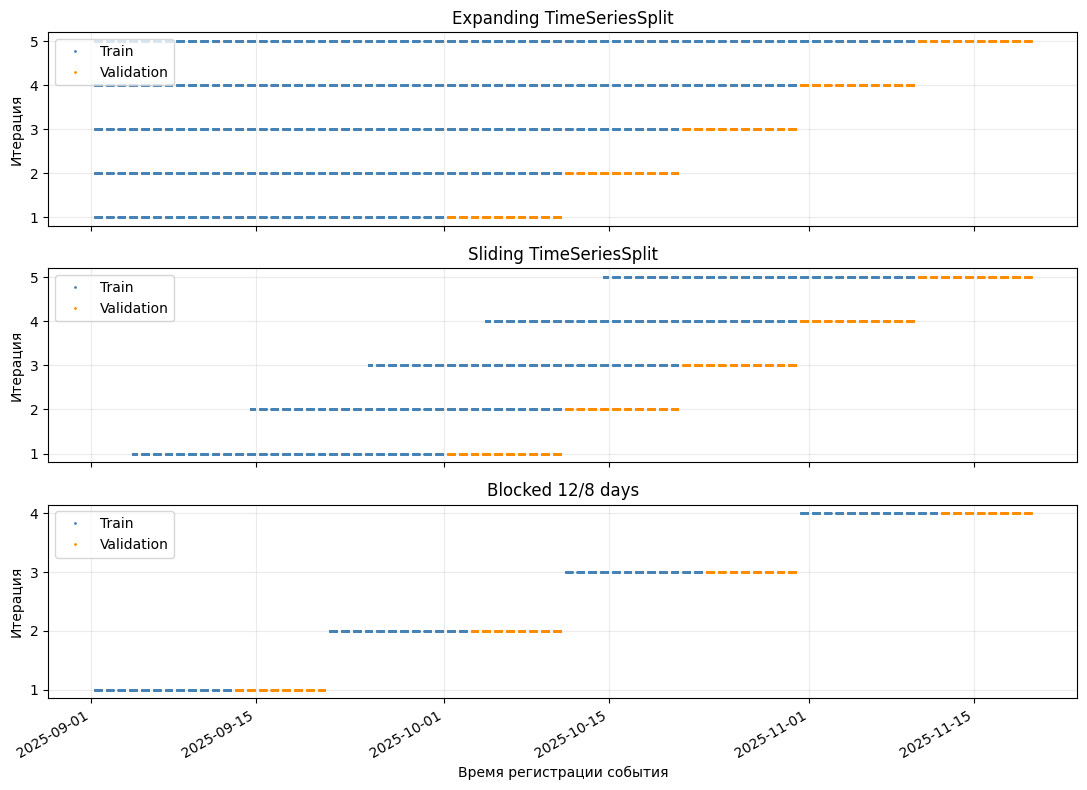

In [14]:
# Синие точки показывают train, оранжевые — validation.
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, (name, splits) in zip(axes, time_splits.items()):
    for fold, (train_idx, val_idx) in enumerate(splits, 1):
        ax.plot(time_pool.iloc[train_idx]['timestamp'],
                np.full(len(train_idx), fold), '.', color='steelblue', markersize=2,
                label='Train' if fold == 1 else None)
        ax.plot(time_pool.iloc[val_idx]['timestamp'],
                np.full(len(val_idx), fold), '.', color='darkorange', markersize=2,
                label='Validation' if fold == 1 else None)
    ax.set_title(name)
    ax.set_ylabel('Итерация')
    ax.set_yticks(range(1, len(splits) + 1))
    ax.legend(loc='upper left')
    ax.grid(alpha=0.25)
axes[-1].set_xlabel('Время регистрации события')
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### Вывод по заданию 4

Хронологические части имеют размеры 1920/480/600/600 и идут строго по времени: train до 3 ноября, validation 4–19 ноября, calibration 20 ноября — 9 декабря, финальный тест 10–29 декабря 2025 года. Доли атак меняются от 8,75% в train до 14,17% в validation, 2,67% в calibration и 14,67% в тесте: временное разбиение не сохраняет баланс классов. На графике расширяющийся train растёт с 900 до 2100 строк, скользящий остаётся размером 800, а каждый блочный цикл использует 12 дней train и следующие 8 дней validation (360 и 240 событий). Оба TimeSeriesSplit проверяют пять непересекающихся блоков по 300 событий, поэтому 900 ранних событий ни разу не входят в validation; у четырёх блочных циклов таких событий 1440. В этом наборе через временные границы не пересекаются группы и инциденты, но сам временной метод этого не гарантирует; в некоторых блоках встречается общая кампания. Графики показывают исторические окна обучения и более поздние окна проверки, полезные для оценки работы на будущих событиях.

## Задание 5. Выбор схемы для режима обучения и вывод SOC — 5 минут, 2 балла

1. Для обучения с учителем, без учителя и только по нормальным данным указать состав четырёх выборок и назначение меток
2. Для нормального режима выделить нормальные события хронологического train и calibration; validation и test сохранить смешанными
3. Составить записку SOC из 5–7 предложений: выбрать схему для будущих событий и для новых инцидентов, назвать её ограничения

**Проверяемый результат:** Таблица трёх режимов, нулевое число атак в normal_train и normal_calibration и обоснованная записка SOC.


In [15]:
# В режиме нормального обучения в fit попадают только события с меткой 0.
normal_train = chron_train[chron_train['is_attack'] == 0].copy()
normal_calibration = time_calibration[time_calibration['is_attack'] == 0].copy()

assert int(normal_train['is_attack'].sum()) == 0
assert int(normal_calibration['is_attack'].sum()) == 0
print('Normal train:', len(normal_train), '| атак:', int(normal_train['is_attack'].sum()))
print('Normal calibration:', len(normal_calibration),
      '| атак:', int(normal_calibration['is_attack'].sum()))
print('Mixed validation:', len(chron_validation),
      '| атак:', int(chron_validation['is_attack'].sum()))
print('Mixed final test:', len(test), '| атак:', int(test['is_attack'].sum()))

mode_table = pd.DataFrame({
    'Режим': ['С учителем', 'Без учителя', 'Только норма'],
    'Train': ['chron_train, смешанный', 'chron_train, смешанный', 'normal_train, только 0'],
    'Validation': ['chron_validation, смешанная'] * 3,
    'Calibration': [
        'time_calibration, смешанная',
        'time_calibration, смешанная',
        'normal_calibration, только 0'
    ],
    'Test': ['final_test, смешанный'] * 3,
    'Использование меток': [
        'Обучение, выбор модели, настройка порога и финальная оценка.',
        'Не в fit; метки validation/test нужны для оценки, calibration — для порога при наличии разметки.',
        '0 отбирает норму; calibration настраивает ложные тревоги, смешанные части проверяют атаки.'
    ]
})
display(mode_table)

Normal train: 1752 | атак: 0
Normal calibration: 584 | атак: 0
Mixed validation: 480 | атак: 68
Mixed final test: 600 | атак: 88


,Режим,Train,Validation,Calibration,Test,Использование меток
0,С учителем,"chron_train, смешанный","chron_validation, смешанная","time_calibration, смешанная","final_test, смешанный","Обучение, выбор модели, настройка порога и фин..."
1,Без учителя,"chron_train, смешанный","chron_validation, смешанная","time_calibration, смешанная","final_test, смешанный",Не в fit; метки validation/test нужны для оцен...
2,Только норма,"normal_train, только 0","chron_validation, смешанная","normal_calibration, только 0","final_test, смешанный",0 отбирает норму; calibration настраивает ложн...


### Вывод по заданию 5 и записка SOC

В обучении с учителем метки `chron_train` нужны для подгонки модели, смешанная validation — для выбора варианта, calibration — для порога, а финальный тест — для однократной итоговой оценки. Без учителя обучение использует те же события без меток; метки поздних частей полезны для внешней оценки, а при их наличии calibration может помочь выбрать порог. В режиме «только норма» обучаются 1752 нормальных события и для настройки допустимой доли ложных тревог выделяются 584 нормальных события calibration; смешанные validation и тест сохраняют 68 и 88 атак. Для обнаружения будущих событий SOC следует предпочесть хронологическую проверку, потому что доля атак и нормальная нагрузка меняются со временем. Для оценки обобщения на новые инциденты нужна группировка по `validation_group`, а для новых кампаний — более строгая группировка на уровне кампании с осмысленным ключом для нормы. Совместная проверка по времени и группам была бы ближе к эксплуатации, поскольку один метод отдельно не гарантирует оба ограничения. Финальный тест следует оставить нетронутым до выбора признаков, модели и порога; дрейф и пересечения кампаний нужно контролировать при каждом обновлении данных.